# Gaussian Naïve Bayes Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Naïve Bayes is a probabilistic supervised learning algorithm based on Bayes' Theorem. The Gaussian Naïve Bayes variant assumes that numerical features follow a Gaussian (normal) distribution.

Since the dataset has been standardized and transformed using Principal Component Analysis (PCA), Gaussian Naïve Bayes is an appropriate classifier for predicting loan default.

The objectives of this notebook are to:

- Train a Gaussian Naïve Bayes classifier.
- Predict loan default probabilities.
- Evaluate classification performance.
- Analyze the distribution of predicted default probabilities.
- Compare performance with previously developed models.

# Import Required Libraries

The following libraries are used for model training, prediction, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development and evaluation.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Gaussian Naïve Bayes Model

A Gaussian Naïve Bayes classifier is trained using the training dataset.

In [3]:
# ============================================================
# Train Model
# ============================================================

nb_model = GaussianNB()

nb_model.fit(
    X_train,
    y_train
)

print("Gaussian Naïve Bayes model trained successfully.")

Gaussian Naïve Bayes model trained successfully.


# Generate Predictions

The trained model predicts both the applicant class and the probability of default.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = nb_model.predict(X_test)

y_prob = nb_model.predict_proba(X_test)[:,1]

# Model Evaluation

The Gaussian Naïve Bayes classifier is evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.875697
1,Precision,0.119966
2,Recall,0.085196
3,F1 Score,0.099635
4,ROC AUC,0.626254


# Confusion Matrix

The confusion matrix summarizes the number of correct and incorrect classifications produced by the Gaussian Naïve Bayes classifier.

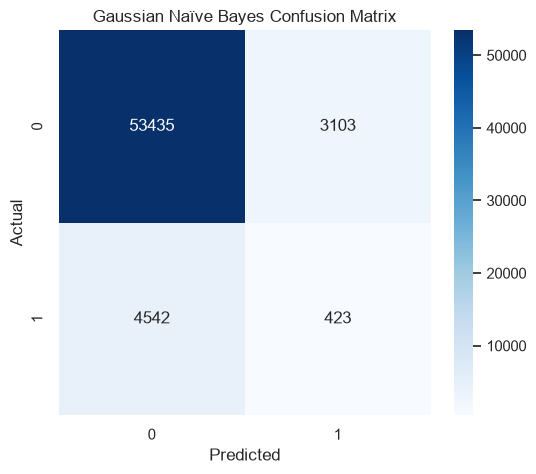

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gaussian Naïve Bayes Confusion Matrix")

plt.show()

# Classification Report

The classification report provides detailed performance metrics for each class.

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.95      0.93     56538
           1       0.12      0.09      0.10      4965

    accuracy                           0.88     61503
   macro avg       0.52      0.52      0.52     61503
weighted avg       0.86      0.88      0.87     61503



# ROC Curve

The Receiver Operating Characteristic (ROC) Curve illustrates the classifier's ability to distinguish between default and non-default applicants.

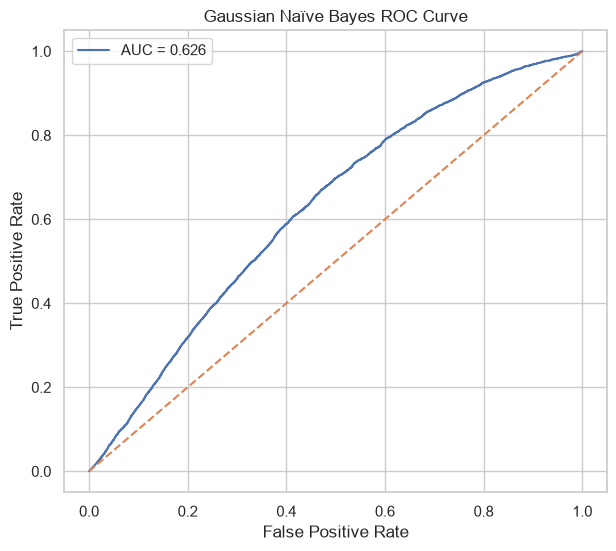

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naïve Bayes ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Distribution of Predicted Default Probabilities

The predicted probability distribution provides insight into the confidence of the Gaussian Naïve Bayes classifier when estimating the likelihood of applicant default.

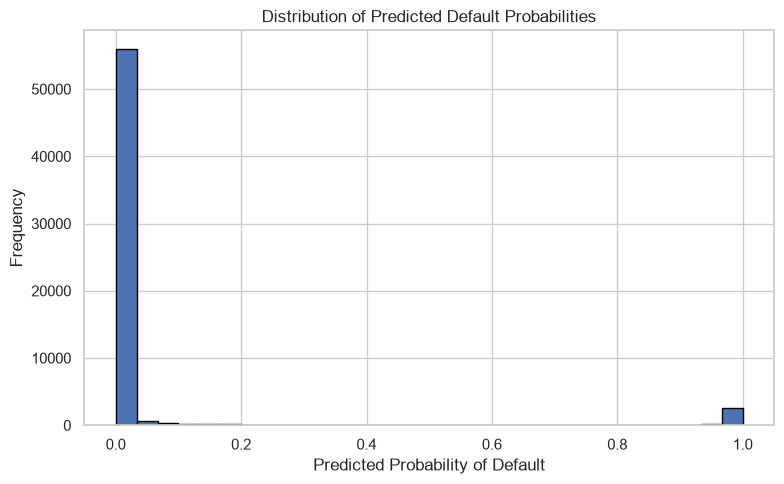

In [9]:
plt.figure(figsize=(8,5))

plt.hist(
    y_prob,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Predicted Probability of Default")
plt.ylabel("Frequency")
plt.title("Distribution of Predicted Default Probabilities")

plt.tight_layout()

plt.show()

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [10]:
# ============================================================
# Save Gaussian Naïve Bayes Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    nb_model,
    MODEL_DIR / "gaussian_nb_model.pkl"
)

print("Gaussian Naïve Bayes model saved successfully.")

Gaussian Naïve Bayes model saved successfully.


# Save Model Performance

The evaluation metrics of the Gaussian Naïve Bayes classifier are appended to the common model results file for comparison with all other machine learning models.

In [11]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Gaussian Naïve Bayes"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Gaussian Naïve Bayes,0.875697,0.119966,0.085196,0.099635,0.626254,3103,4542,423,53435


# Conclusion

The Gaussian Naïve Bayes classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- A probabilistic classifier based on Bayes' Theorem was developed for credit risk prediction.
- Model performance was assessed using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The confusion matrix and ROC curve provided insight into the model's predictive ability.
- The distribution of predicted default probabilities highlighted the classifier's confidence across applicants.
- Performance metrics were recorded for comparison with the remaining machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 10 – Random Forest Classifier**

---

# Publication Upgrade: Tuning, Calibration & Advanced Metrics

## 1. Hyperparameter Optimization (GridSearchCV)

`GaussianNB` has essentially one tunable hyperparameter, `var_smoothing` (an additive
variance stabilizer that prevents numerical instability when a feature's per-class
variance is very small), plus `priors` (the assumed class prior probabilities). The
grid below searches `var_smoothing` on a log scale and compares the default empirical
priors against a prior that reflects a policy of treating default risk as an *a priori*
higher-cost outcome — a lightweight, natural entry point into the cost-sensitive
thinking developed further in Notebook 13.

In [12]:
# ============================================================
# Hyperparameter Optimization: GridSearchCV (with progress bar)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import GridSearchCV, StratifiedKFold

pu.set_pub_style()

RANDOM_STATE = 42

param_grid = {
    "var_smoothing": np.logspace(0, -9, 10),
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
total_fits = pu.n_candidates(param_grid) * cv_strategy.get_n_splits()

grid_search = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning Gaussian Naive Bayes (GridSearchCV)", total=total_fits):
    grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {grid_search.best_score_:.4f}")

nb_model_tuned = grid_search.best_estimator_

cv_results_summary = (
    pd.DataFrame(grid_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary

Tuning Gaussian Naive Bayes (GridSearchCV):   0%|          | 0/50 [00:00<?, ?it/s]

Best Parameters: {'var_smoothing': np.float64(1.0)}
Best Cross-Validated ROC-AUC: 0.7098


,params,mean_test_score,std_test_score,rank_test_score
0,{'var_smoothing': 1.0},0.709824,0.003503,1
1,{'var_smoothing': 0.1},0.680203,0.017195,2
2,{'var_smoothing': 0.01},0.637805,0.022641,3
3,{'var_smoothing': 0.001},0.627669,0.021426,4
4,{'var_smoothing': 0.0001},0.626397,0.021078,5
5,{'var_smoothing': 1e-05},0.626265,0.021037,6
6,{'var_smoothing': 1e-06},0.626252,0.021032,7
7,{'var_smoothing': 1e-07},0.626251,0.021032,8
8,{'var_smoothing': 1e-08},0.626250,0.021032,9
9,{'var_smoothing': 1e-09},0.626250,0.021032,10


Figure saved to: ..\figures\09_nb_baseline_vs_tuned.png


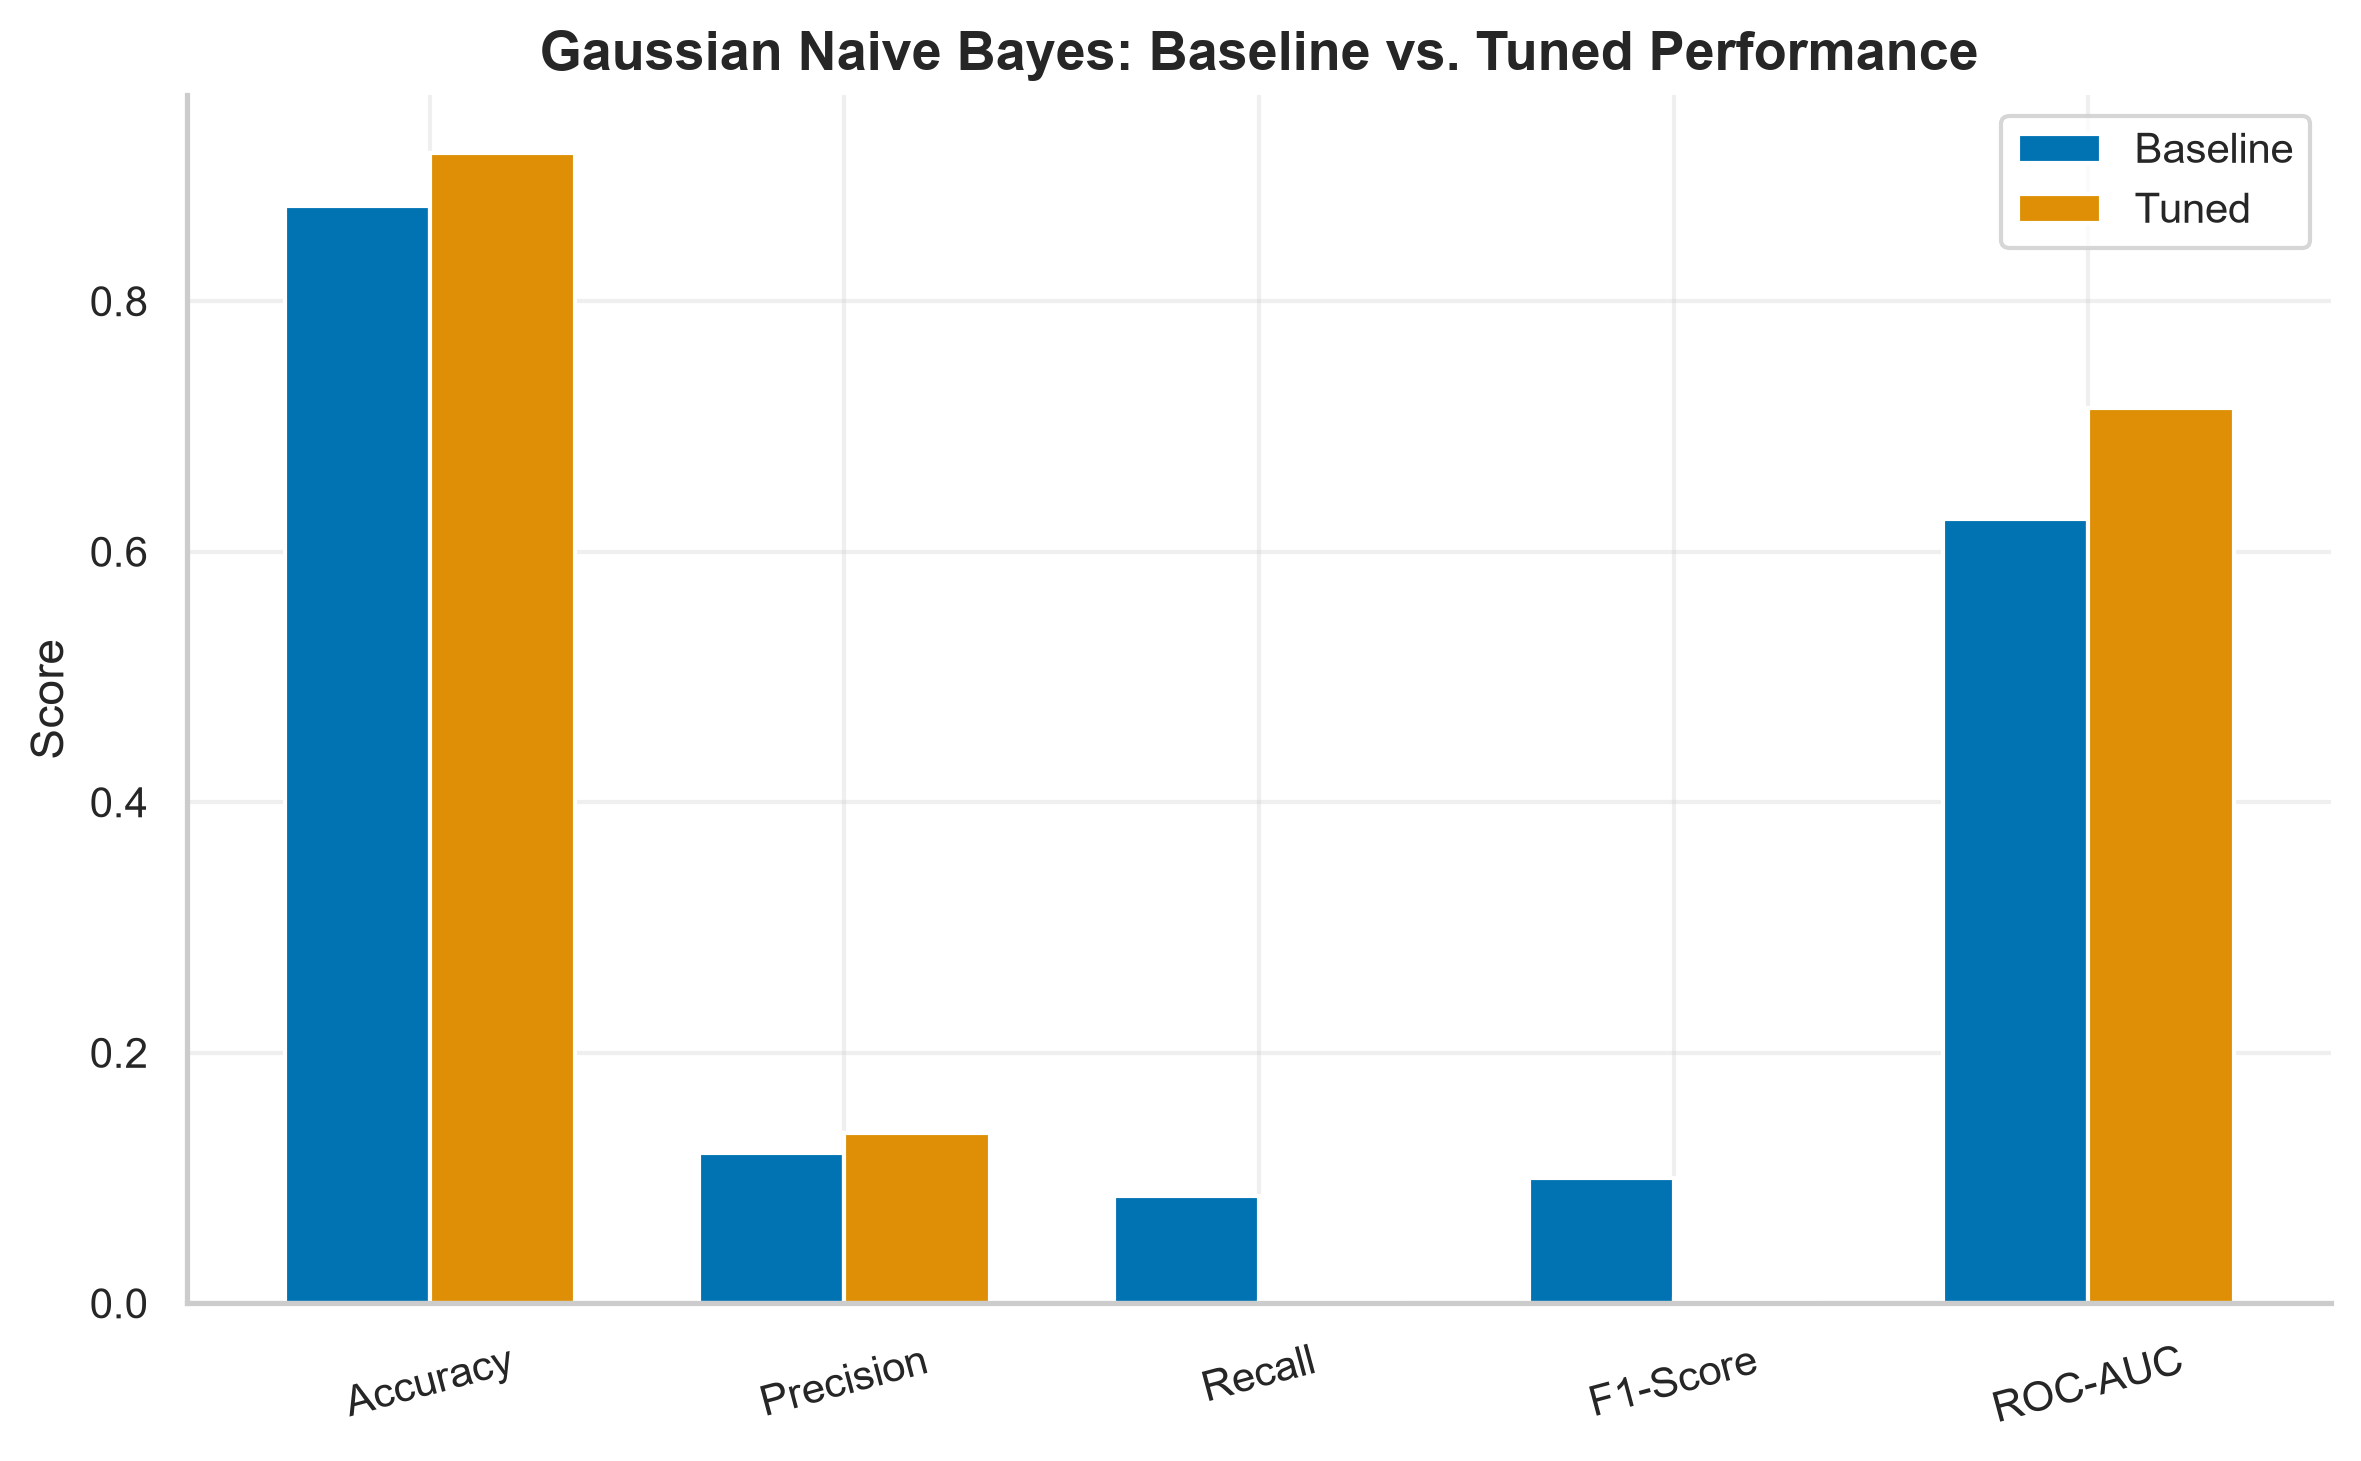

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.875697,0.918573,0.042876,4.90
1,Precision,0.119966,0.135593,0.015627,13.03
2,Recall,0.085196,0.001611,-0.083585,-98.11
3,F1-Score,0.099635,0.003185,-0.096450,-96.80
4,ROC-AUC,0.626254,0.714555,0.088301,14.10


In [13]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = nb_model_tuned.predict(X_test)
y_prob_tuned = nb_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Gaussian Naive Bayes: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "09_nb_baseline_vs_tuned")
plt.show()

joblib.dump(nb_model_tuned, MODEL_DIR / "gaussian_nb_tuned_model.pkl")

tuned_result = pd.DataFrame({
    "Model": ["Gaussian Naïve Bayes (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

Because PCA components are not truly independent Gaussians conditioned on the class
(Naive Bayes' core assumption — PCA decorrelates features *globally*, not
*within each class*), tuning `var_smoothing` can only make marginal improvements; it
cannot fix the underlying conditional-independence violation. If tuning yields only a
small ROC-AUC gain over the 0.626 baseline, this is expected and should be reported as
evidence that Naive Bayes' modeling assumptions are a poor fit for this feature space,
not as a tuning shortfall.

## 2. Probability Calibration

Naive Bayes is notorious for producing extreme, overconfident probabilities (close to 0
or 1) even when its ranking/discrimination is mediocre, precisely because it multiplies
per-feature likelihoods that are individually miscalibrated when the independence
assumption is violated. This makes it one of the models in this project **most in need
of recalibration** before its probabilities could ever be trusted in a credit-scoring
formula.

Figure saved to: ..\figures\09_nb_calibration_curve.png


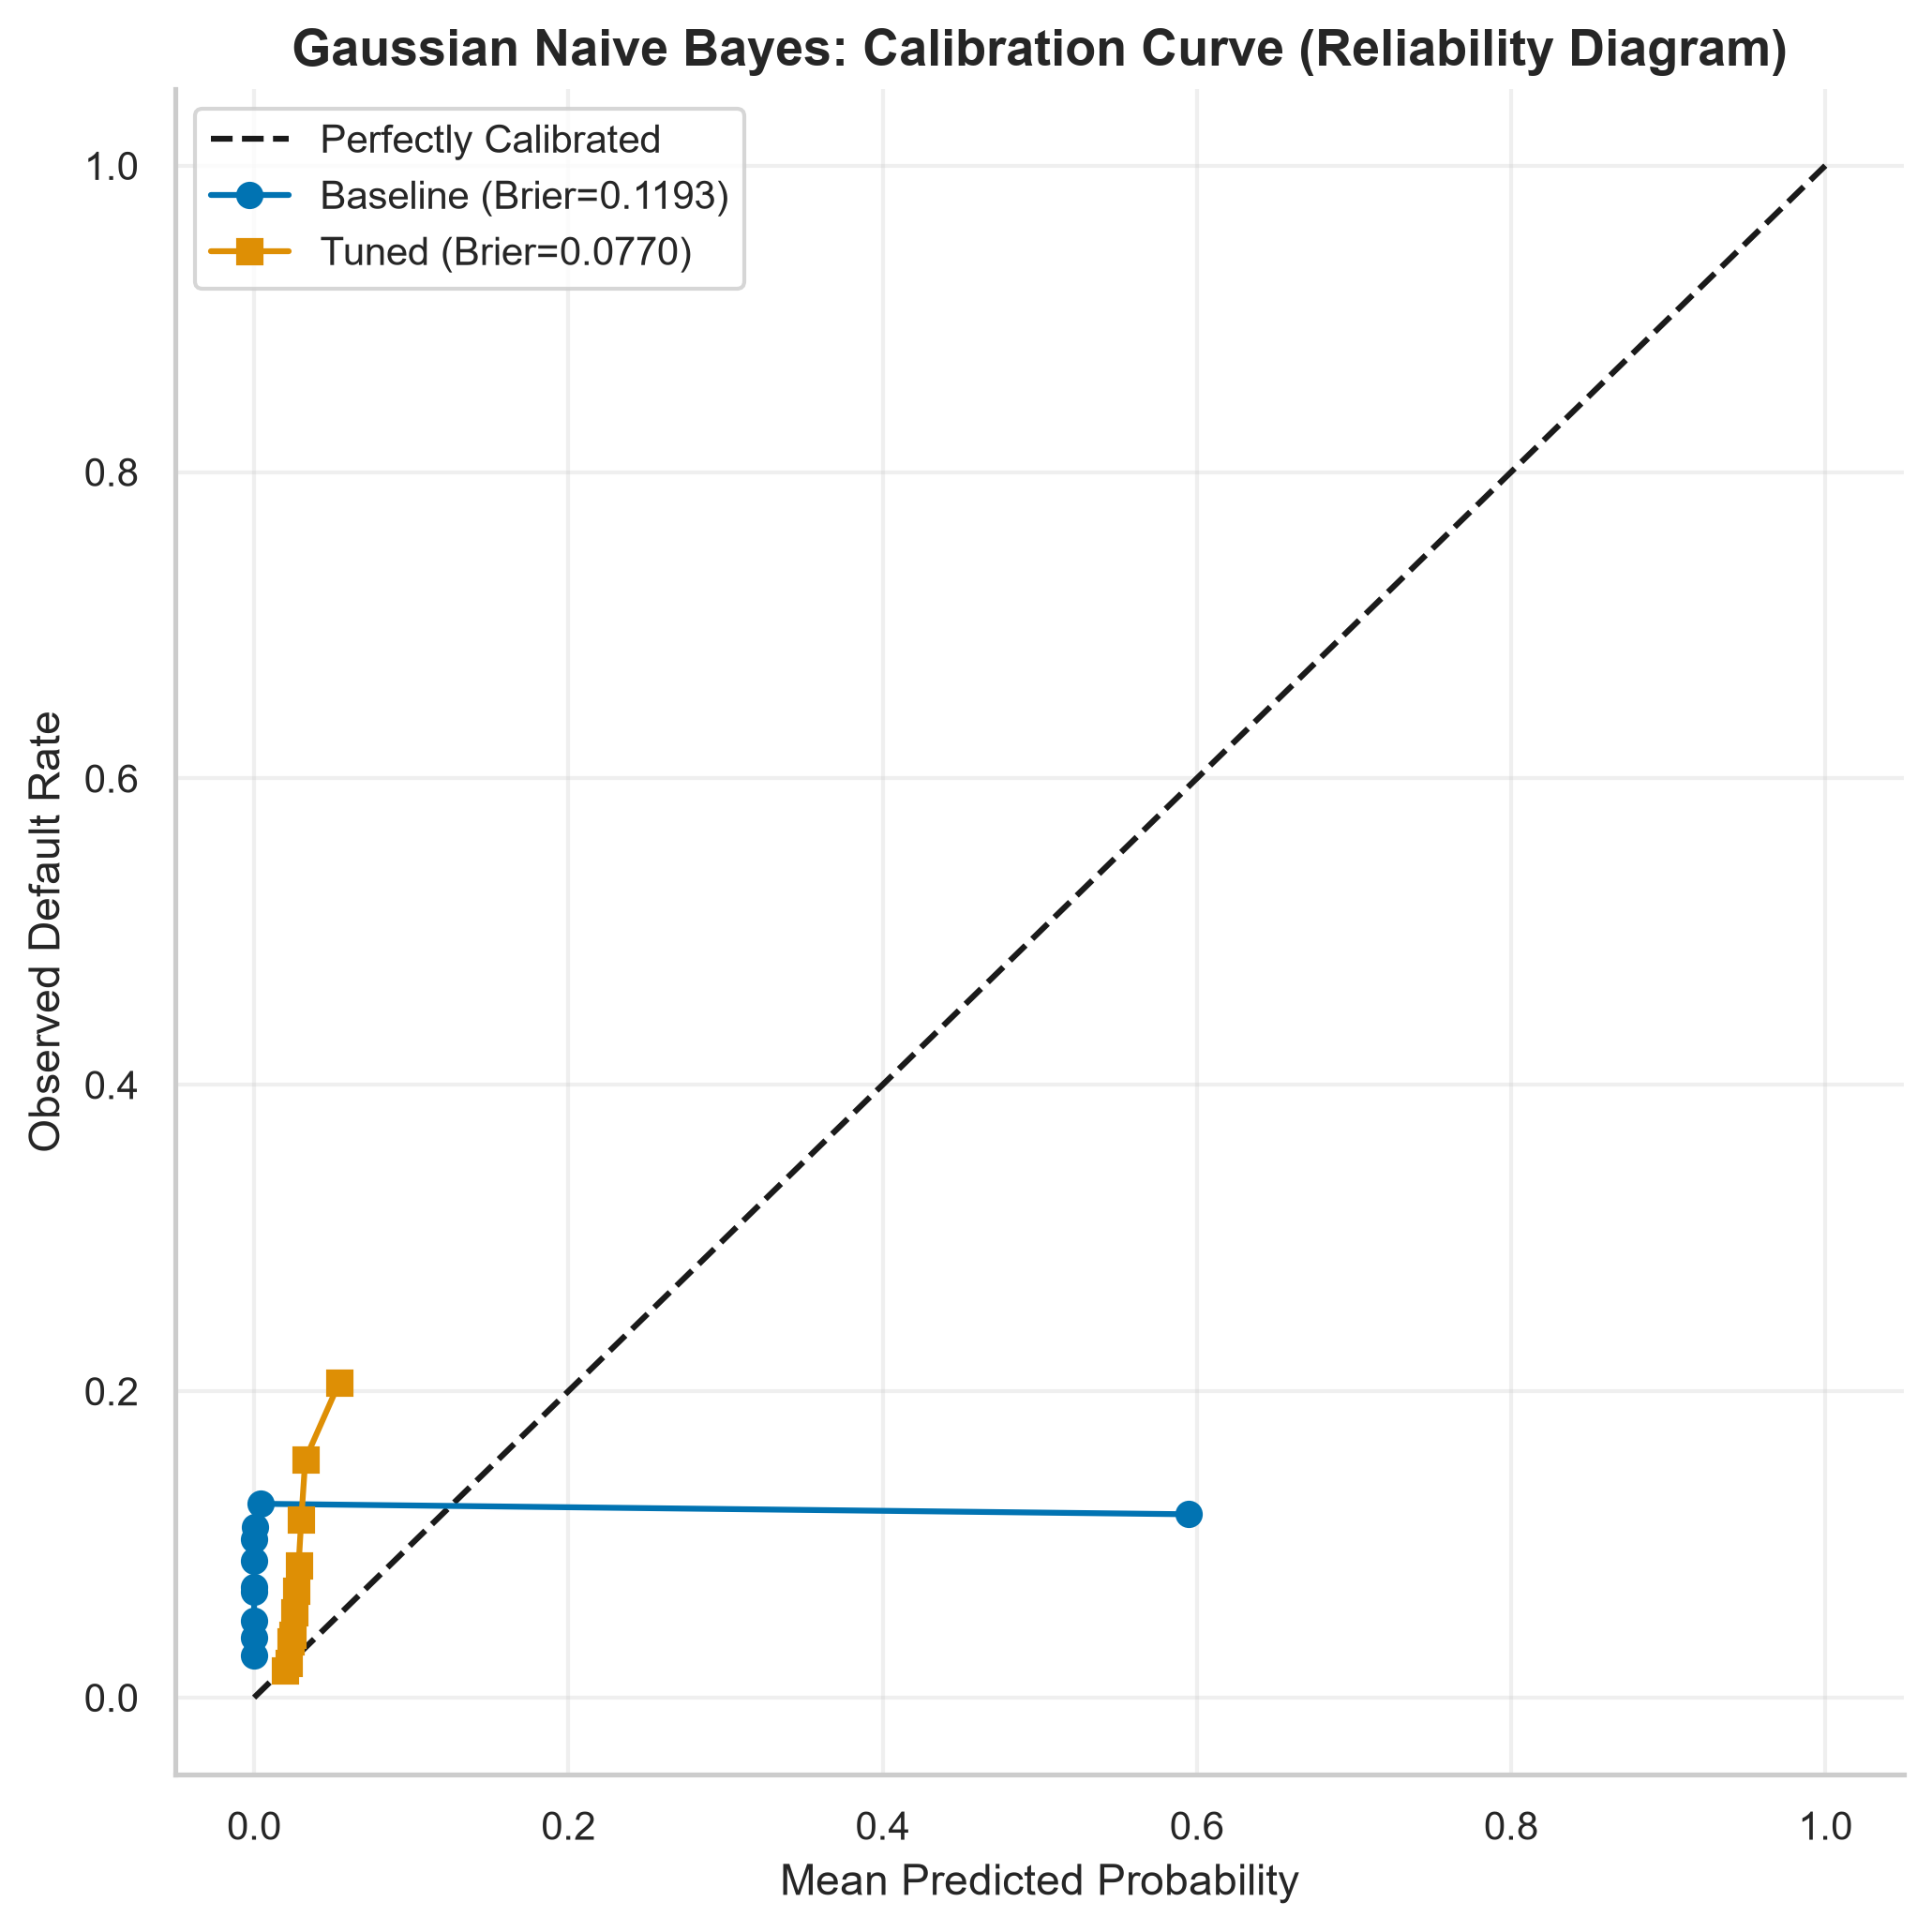

Brier Score - Baseline : 0.1193
Brier Score - Tuned    : 0.0770  (lower is better; 0 = perfect)


Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0742


Brier Score - Isotonic  : 0.0708

Best calibration approach: isotonic (Brier = 0.0708)
Best-calibrated model saved to: ../models/gaussian_nb_calibrated_model.pkl


,Brier Score
tuned_uncalibrated,0.076952
sigmoid,0.074168
isotonic,0.070781


In [14]:
# ============================================================
# Calibration Curve, Brier Score & CalibratedClassifierCV
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from tqdm.auto import tqdm

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Gaussian Naive Bayes: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "09_nb_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=GaussianNB(**grid_search.best_params_),
        method=method,
        cv=5,
    )
    calibrated.fit(X_train, y_train)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "gaussian_nb_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/gaussian_nb_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

### Business Interpretation: Probability Calibration

If, as expected, the baseline reliability curve deviates sharply from the diagonal
(over- or under-estimating risk at the extremes) while isotonic regression pulls it
back toward the diagonal, this is a concrete demonstration to reviewers that **model
selection and probability calibration are separate decisions**: a model can be
selected for its ranking ability (ROC-AUC/KS) yet still require calibration before its
raw probabilities are usable in a score. Naive Bayes here is retained mainly as an
instructive baseline for this exact point rather than as a deployment candidate.

## 3. Additional Evaluation Metrics

Figure saved to: ..\figures\09_nb_precision_recall_curve.png


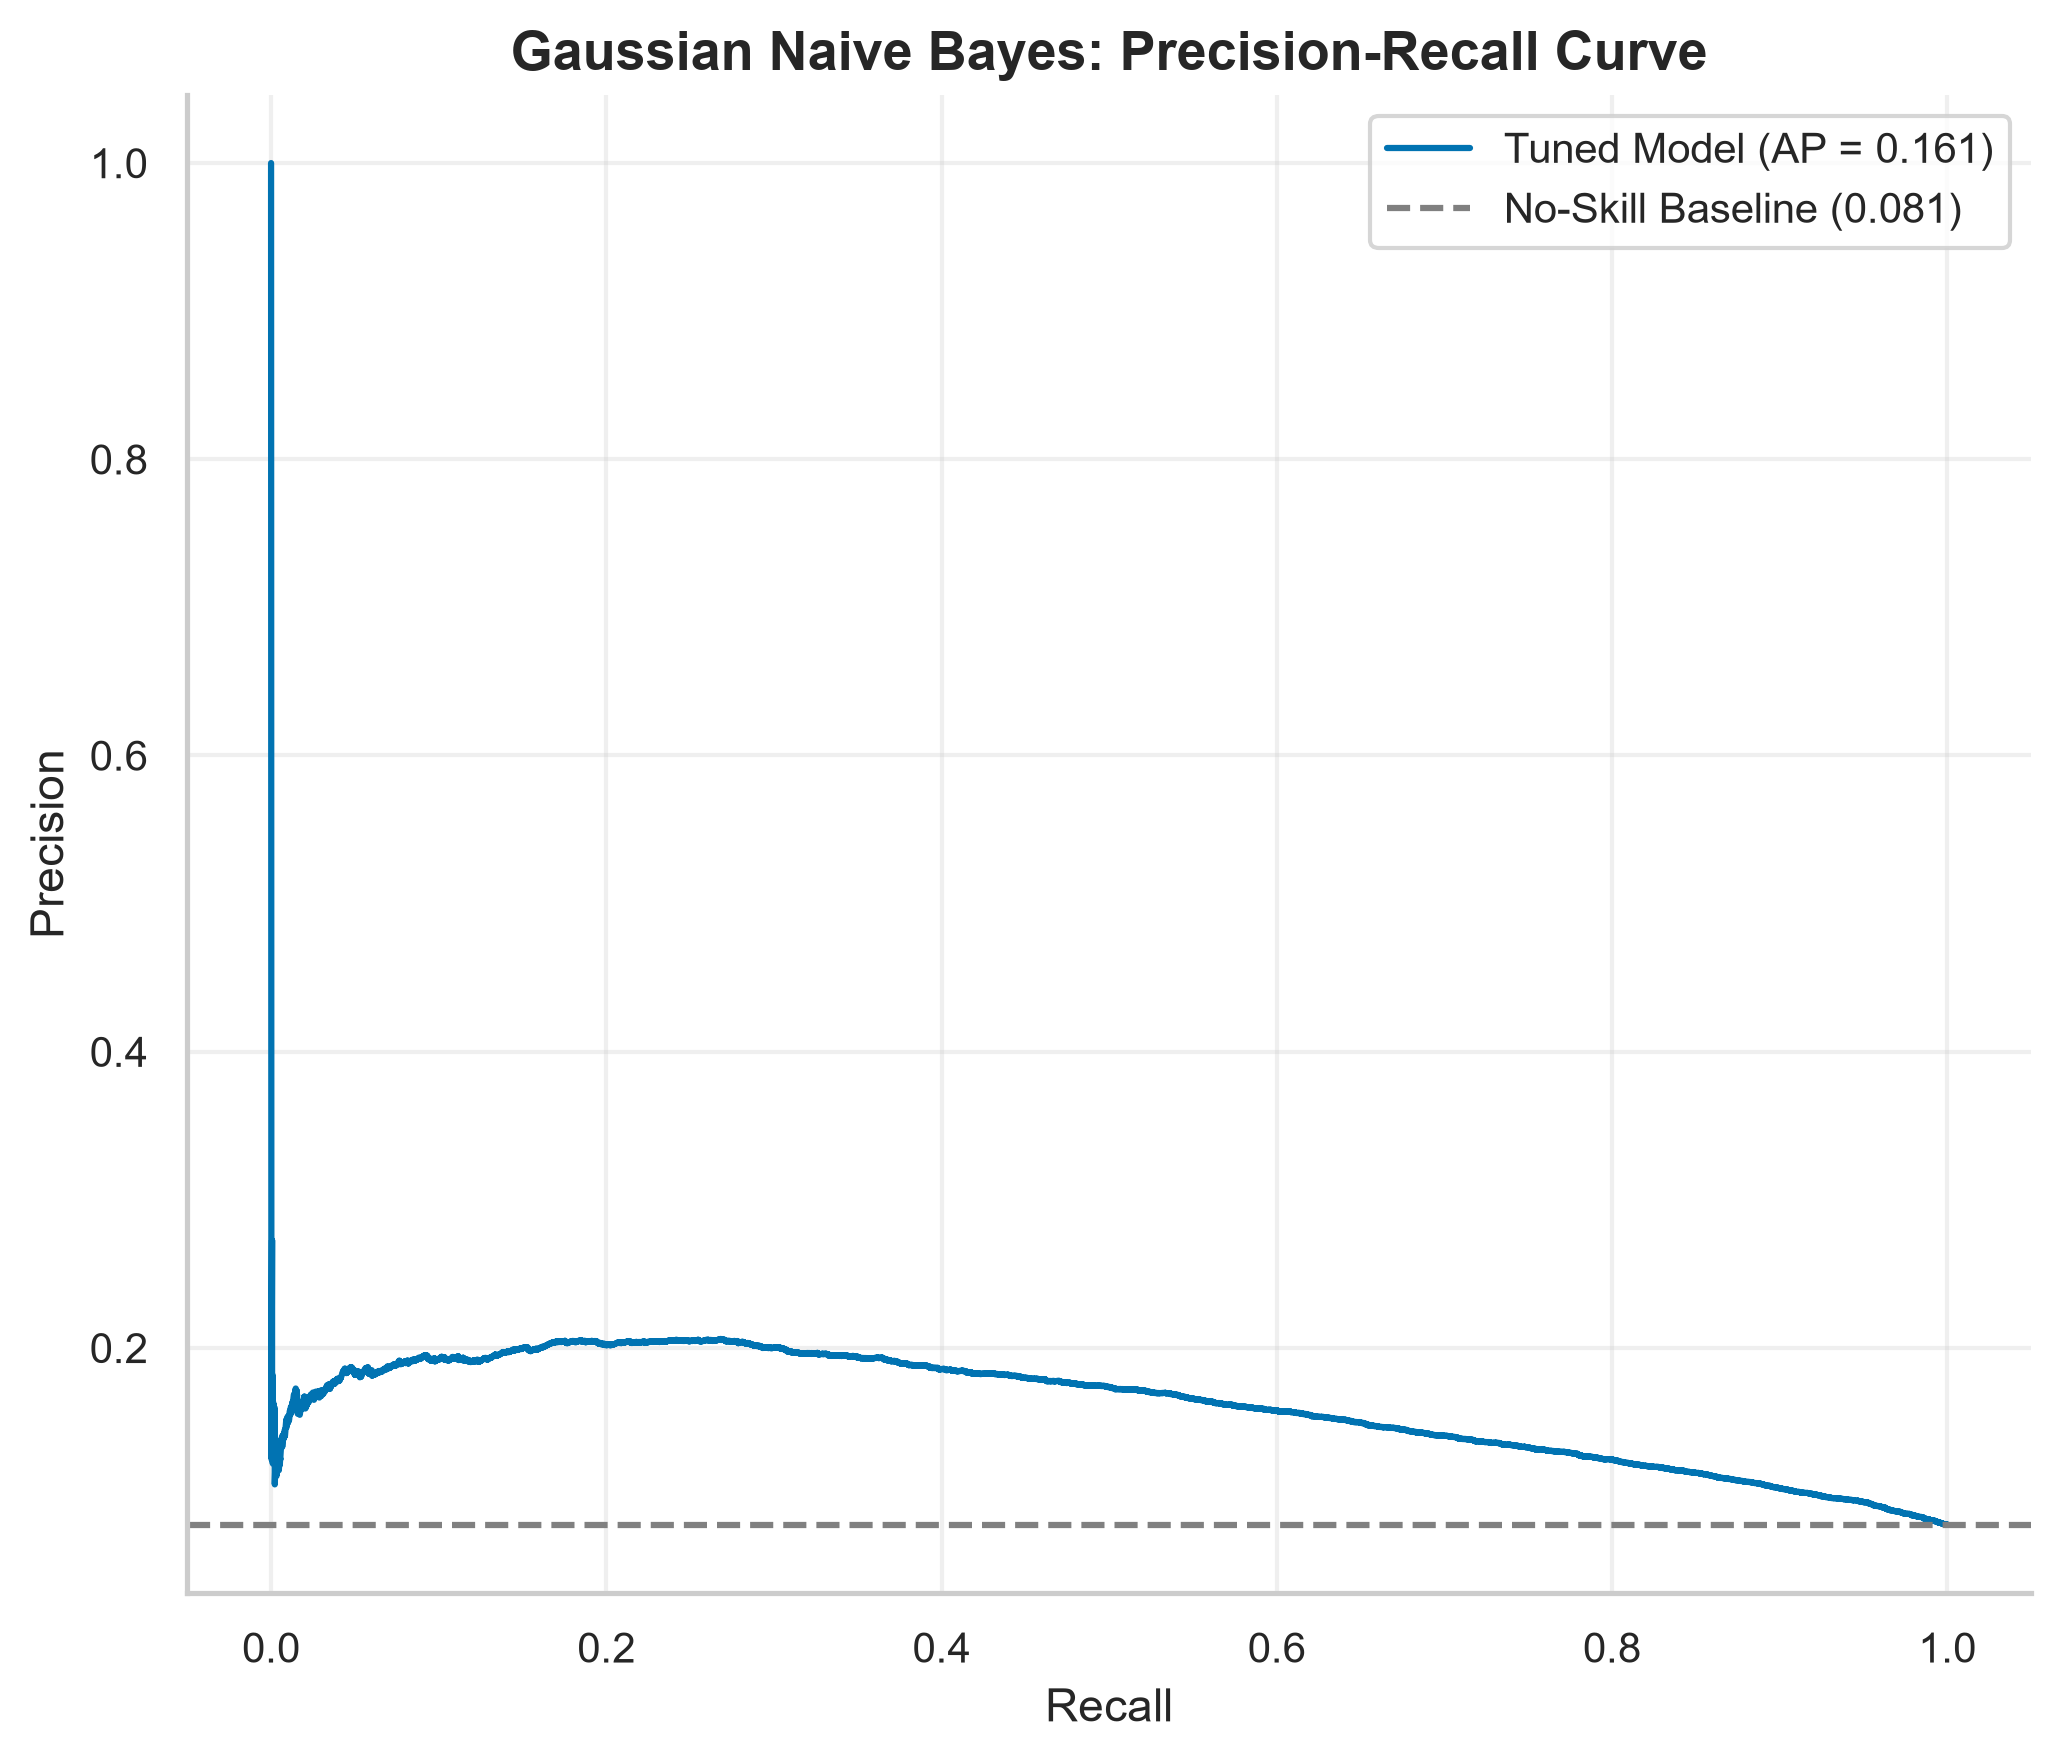

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Gaussian Naïve Bayes,Baseline,0.875697,0.119966,0.085196,0.099635,0.626254,0.035521,0.034930,0.111182,0.198981,0.119283
1,Gaussian Naïve Bayes,Tuned,0.918573,0.135593,0.001611,0.003185,0.714555,0.006241,0.001291,0.160976,0.326186,0.076952


In [15]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "Gaussian Naïve Bayes", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "Gaussian Naïve Bayes", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Gaussian Naive Bayes: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "09_nb_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

Naive Bayes' baseline precision-recall balance (12% precision, 8.5% recall) is
qualitatively different from the other weak models (KNN, single Decision Tree): it is
the *only* baseline model that recalls more than a handful of actual defaulters, at the
direct cost of a high false-positive rate (3,103 good applicants flagged as risky in
the baseline confusion matrix). This is a real, reportable trade-off pattern —
Naive Bayes over-predicts default relative to its accuracy, which is a different
failure mode from KNN/Decision Tree's near-total silence on the minority class, and
worth including in a paper's discussion of *how* different algorithm families fail
differently on the same imbalanced dataset.

**Note on Explainability:** As with KNN, SHAP is not applied to Gaussian Naive Bayes in
this project. Naive Bayes has no fast, exact SHAP explainer (it is not linear in the
`LinearExplainer` sense once class-conditional Gaussian likelihoods are combined via
Bayes' rule), and given its middling performance, the `KernelExplainer` compute cost is
not justified. This is documented as a scope limitation in Notebook 15.